# Лабораторная работа «Разведочный анализ данных (EDA). Визуализация данных (Pandas, Matplotlib, Seaborn)»

**Цель работы:** освоить методы разведочного анализа данных, визуализацию распределений, выявление трендов и пропусков.

**Набор данных:** `StudentsPerformance.csv` — результаты экзаменов 1000 школьников (math / reading / writing score) и сведения об учениках (пол, группа, образование родителей, тип питания, подготовительный курс).

**Задачи работы:**
1. Провести первичный анализ структуры данных.
2. Вычислить основные статистические характеристики.
3. Построить визуализации распределений признаков.
4. Выявить тренды и зависимости между переменными.
5. Обнаружить пропуски и аномалии.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 12


df = pd.read_csv("StudentsPerformance.csv")
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## 1. Первичный анализ структуры данных

In [2]:
print("Размер таблицы (строк, столбцов):", df.shape)
print()
df.info()

Размер таблицы (строк, столбцов): (1000, 8)

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [3]:
# Категориальные признаки: число уникальных значений и сами значения
cat_cols = df.select_dtypes(exclude="number").columns
for c in cat_cols:
    print(f"{c:30s} ({df[c].nunique()}):", sorted(df[c].unique()))

gender                         (2): ['female', 'male']
race/ethnicity                 (5): ['group A', 'group B', 'group C', 'group D', 'group E']
parental level of education    (6): ["associate's degree", "bachelor's degree", 'high school', "master's degree", 'some college', 'some high school']
lunch                          (2): ['free/reduced', 'standard']
test preparation course        (2): ['completed', 'none']


## 2. Основные статистические характеристики

In [4]:
num_cols = df.select_dtypes(include="number").columns.tolist()
stats = df[num_cols].describe().T
stats["median"] = df[num_cols].median()
stats["skew"] = df[num_cols].skew()
stats["kurtosis"] = df[num_cols].kurt()
stats.round(2)

,count,mean,std,min,25%,50%,75%,max,median,skew,kurtosis
math score,1000.0,66.09,15.16,0.0,57.00,66.0,77.0,100.0,66.0,-0.28,0.27
reading score,1000.0,69.17,14.60,17.0,59.00,70.0,79.0,100.0,70.0,-0.26,-0.07
writing score,1000.0,68.05,15.20,10.0,57.75,69.0,79.0,100.0,69.0,-0.29,-0.03


In [5]:
# Описание категориальных признаков
df[cat_cols].describe().T

,count,unique,top,freq
gender,1000,2,female,518
race/ethnicity,1000,5,group C,319
parental level of education,1000,6,some college,226
lunch,1000,2,standard,645
test preparation course,1000,2,none,642


## 5 (часть). Пропуски и дубликаты

In [6]:
print("Пропусков по столбцам:")
print(df.isna().sum())
print()
print("Всего пропусков:", df.isna().sum().sum())
print("Полных дубликатов строк:", df.duplicated().sum())

Пропусков по столбцам:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Всего пропусков: 0
Полных дубликатов строк: 0


## 3. Визуализация распределений: Pandas

### 3.1. Столбчатая диаграмма для столбца `parental level of education`

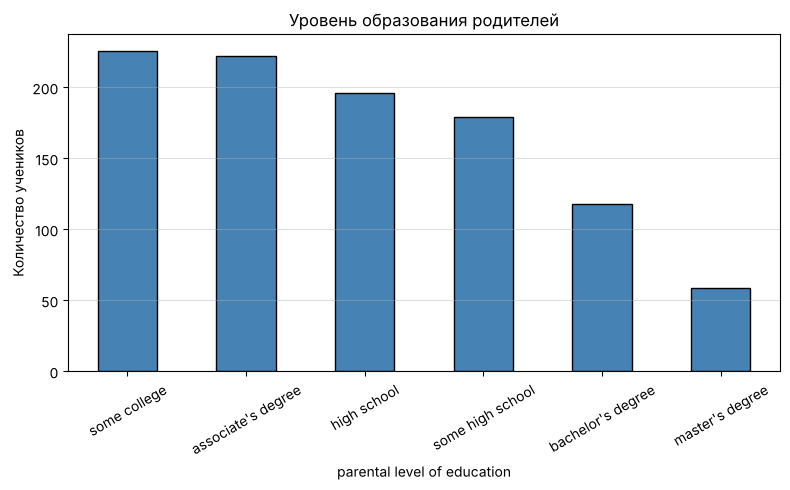

In [7]:
ax = df["parental level of education"].value_counts().plot(
    kind="bar", color="steelblue", edgecolor="black", figsize=(8, 5), rot=30)
ax.set_title("Уровень образования родителей")
ax.set_xlabel("parental level of education")
ax.set_ylabel("Количество учеников")
ax.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

### 3.2. Круговая диаграмма для столбца `race/ethnicity`

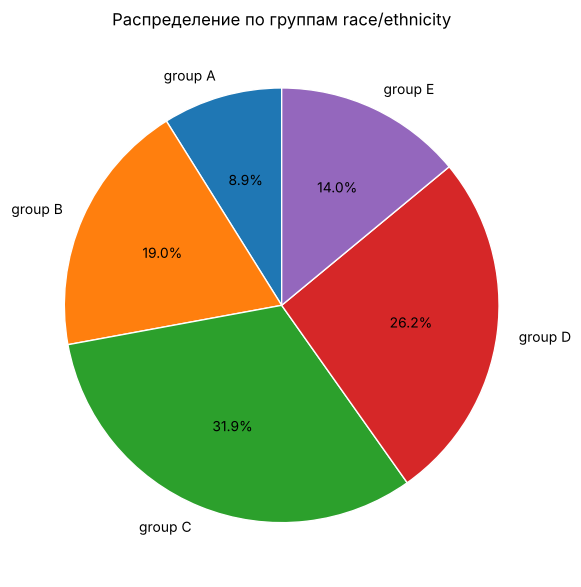

In [8]:
ax = df["race/ethnicity"].value_counts().sort_index().plot(
    kind="pie", autopct="%1.1f%%", figsize=(6, 6), startangle=90,
    wedgeprops={"edgecolor": "white"})
ax.set_title("Распределение по группам race/ethnicity")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 3.3. Гистограммы для всех числовых столбцов (один вызов функции — один рисунок)

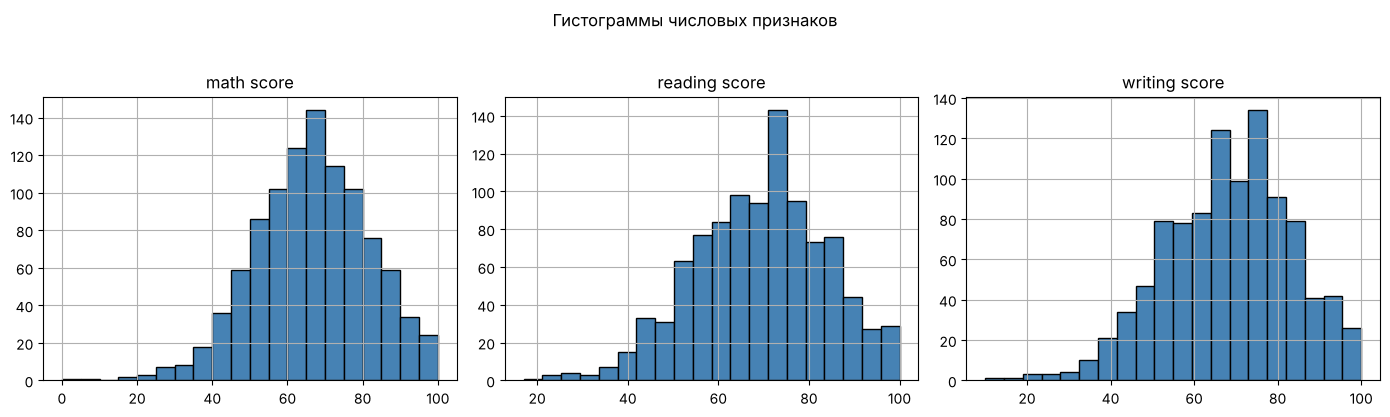

In [9]:
axes = df.hist(bins=20, figsize=(14, 4), layout=(1, 3), color="steelblue", edgecolor="black")
plt.suptitle("Гистограммы числовых признаков", y=1.03)
plt.tight_layout()
plt.show()

## 4. Matplotlib: набор графиков (`subplot(32X)`)

Рисунок состоит из 6 графиков (3 строки × 2 столбца), номера X = 1…6 идут слева направо, сверху вниз.

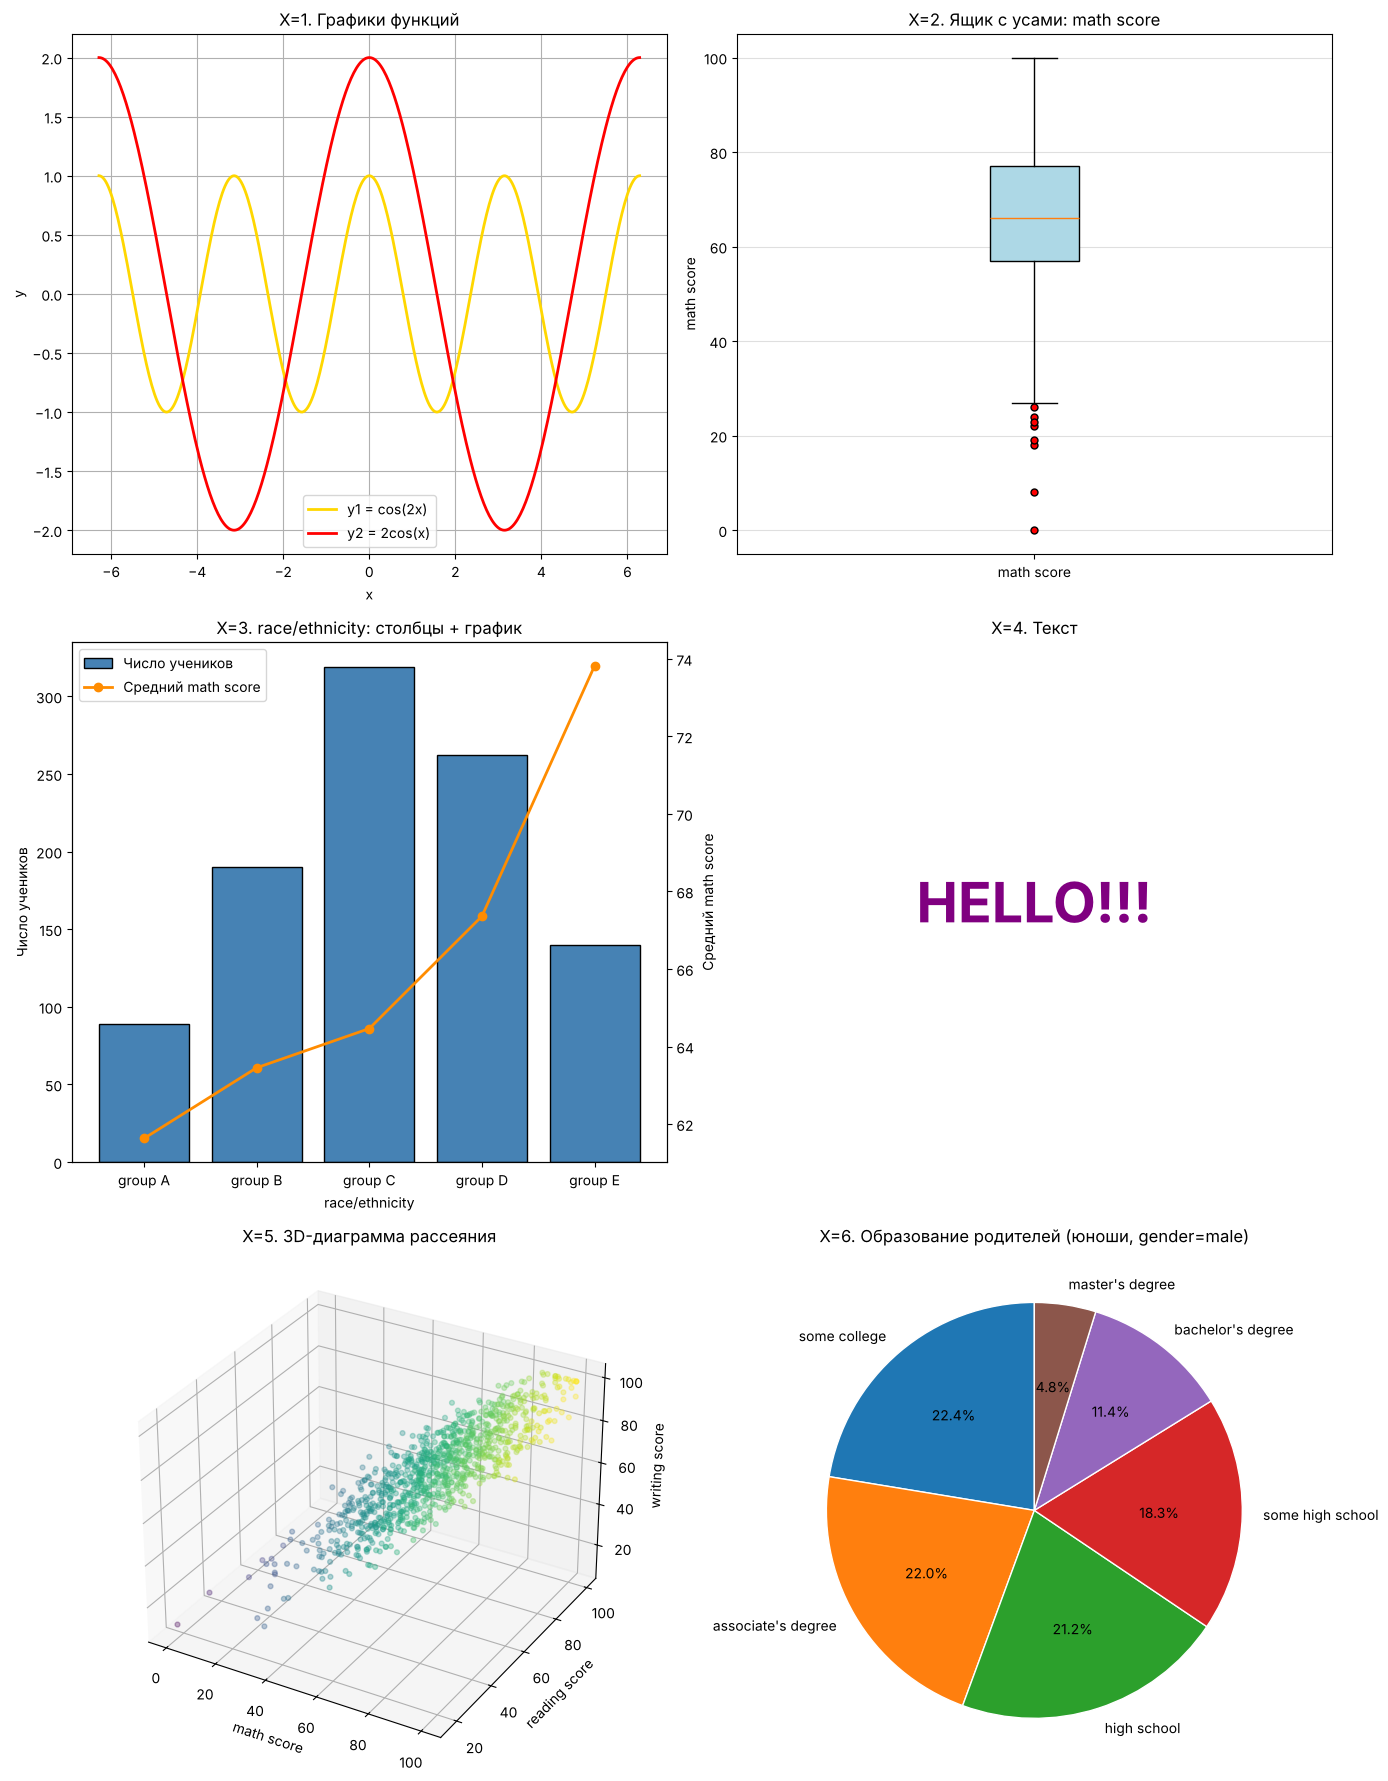

In [10]:
fig = plt.figure(figsize=(14, 18))

# --- X=1. Графики функций y1 = cos(2x), y2 = 2cos(x) ---------------------
ax1 = plt.subplot(321)
x = np.linspace(-2 * np.pi, 2 * np.pi, 400)
ax1.plot(x, np.cos(2 * x), color="gold", linewidth=2, label="y1 = cos(2x)")
ax1.plot(x, 2 * np.cos(x), color="red", linewidth=2, label="y2 = 2cos(x)")
ax1.set_title("X=1. Графики функций")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.grid(True)
ax1.legend()

# --- X=2. «Ящик с усами» для math score ----------------------------------
ax2 = plt.subplot(322)
ax2.boxplot(df["math score"], patch_artist=True,
            boxprops=dict(facecolor="lightblue"),
            flierprops=dict(marker="o", markerfacecolor="red", markersize=5))
ax2.set_title("X=2. Ящик с усами: math score")
ax2.set_ylabel("math score")
ax2.set_xticks([1], ["math score"])
ax2.grid(axis="y", alpha=0.4)

# --- X=3. Комбинированный график: столбцы + линия для race/ethnicity ------
ax3 = plt.subplot(323)
cnt = df["race/ethnicity"].value_counts().sort_index()
mean_math = df.groupby("race/ethnicity")["math score"].mean().loc[cnt.index]
ax3.bar(cnt.index, cnt.values, color="steelblue", edgecolor="black", label="Число учеников")
ax3.set_ylabel("Число учеников")
ax3.set_xlabel("race/ethnicity")
ax3b = ax3.twinx()
ax3b.plot(cnt.index, mean_math.values, color="darkorange", marker="o", linewidth=2,
          label="Средний math score")
ax3b.set_ylabel("Средний math score")
ax3.set_title("X=3. race/ethnicity: столбцы + график")
h1, l1 = ax3.get_legend_handles_labels()
h2, l2 = ax3b.get_legend_handles_labels()
ax3.legend(h1 + h2, l1 + l2, loc="upper left")

# --- X=4. Текст HELLO!!! --------------------------------------------------
ax4 = plt.subplot(324)
ax4.text(0.5, 0.5, "HELLO!!!", fontsize=40, color="purple", fontweight="bold",
         ha="center", va="center")
ax4.set_title("X=4. Текст")
ax4.axis("off")

# --- X=5. 3D-диаграмма рассеяния math + reading + writing -----------------
ax5 = fig.add_subplot(3, 2, 5, projection="3d")
ax5.scatter(df["math score"], df["reading score"], df["writing score"],
            c=df["math score"], cmap="viridis", alpha=0.6, s=12)
ax5.set_xlabel("math score")
ax5.set_ylabel("reading score")
ax5.set_zlabel("writing score")
ax5.set_title("X=5. 3D-диаграмма рассеяния")

# --- X=6. Круговая диаграмма для parental level of education (gender=male) -
ax6 = plt.subplot(326)
male_edu = df.loc[df["gender"] == "male", "parental level of education"].value_counts()
ax6.pie(male_edu.values, labels=male_edu.index, autopct="%1.1f%%", startangle=90,
        wedgeprops={"edgecolor": "white"})
ax6.set_title("X=6. Образование родителей (юноши, gender=male)")

plt.tight_layout()
plt.show()

### Выбросы по math score (ответ на вопрос к X=2)

In [11]:
q1, q3 = df["math score"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df.loc[(df["math score"] < low) | (df["math score"] > high), "math score"]
print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
print(f"Границы «усов»: [{low}; {high}]")
print(f"Выбросов: {len(outliers)}; значения: {sorted(outliers.tolist())}")

Q1 = 57.0, Q3 = 77.0, IQR = 20.0
Границы «усов»: [27.0; 107.0]
Выбросов: 8; значения: [0, 8, 18, 19, 22, 23, 24, 26]


**Вывод по X=2.** Да, выбросы есть: на диаграмме красными точками отмечены экстремально **низкие** оценки по математике (меньше нижней границы 27 баллов). Это 8 учеников с оценками 0, 8, 18, 19, 22, 23, 24 и 26. Выбросов сверху нет: верхняя граница 107 превышает максимально возможный балл (100).

## 5. Seaborn

### 5.1. `pairplot`: гистограммы по диагонали + диаграммы рассеяния

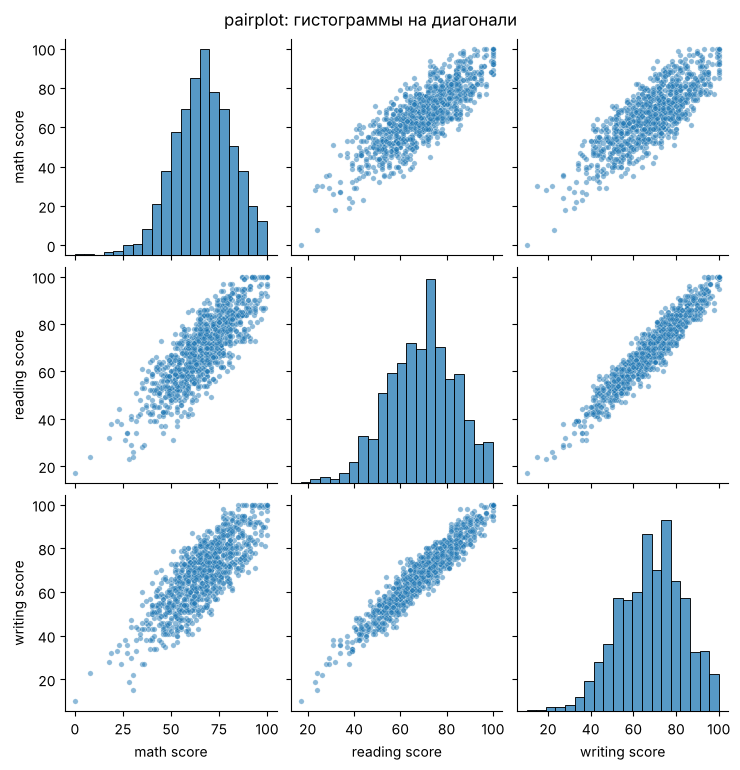

In [12]:
g = sns.pairplot(df, diag_kind="hist", plot_kws={"alpha": 0.5, "s": 15},
                 diag_kws={"bins": 20})
g.figure.suptitle("pairplot: гистограммы на диагонали", y=1.02)
plt.show()

### 5.2. `pairplot`: KDE по диагонали + кластеризация по полу (`hue="gender"`)

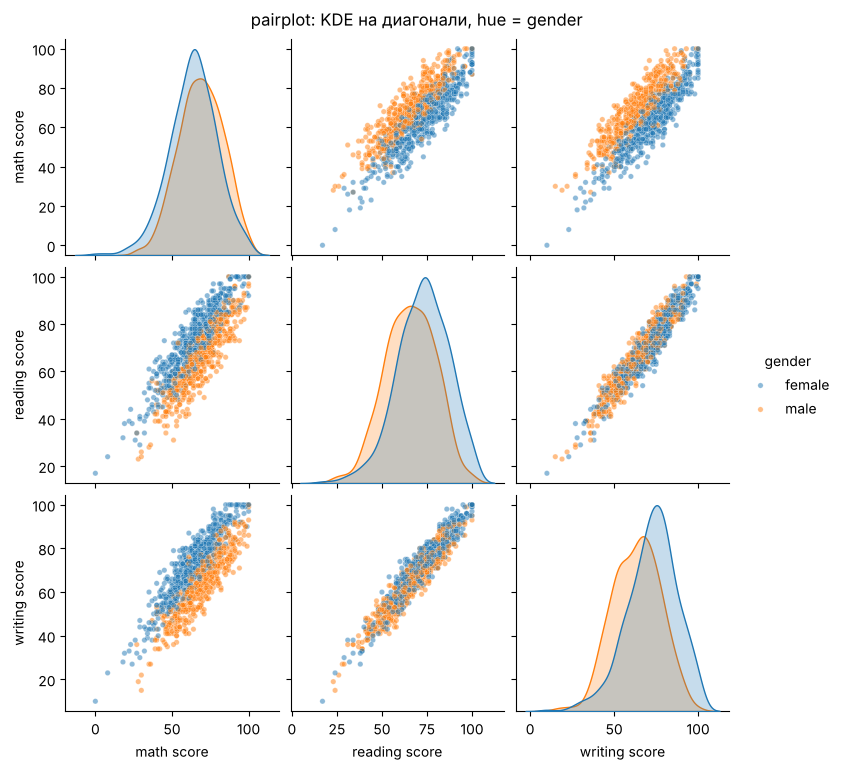

In [13]:
g = sns.pairplot(df, hue="gender", diag_kind="kde", plot_kws={"alpha": 0.5, "s": 15})
g.figure.suptitle("pairplot: KDE на диагонали, hue = gender", y=1.02)
plt.show()

### 5.3. Тепловая карта корреляций числовых столбцов

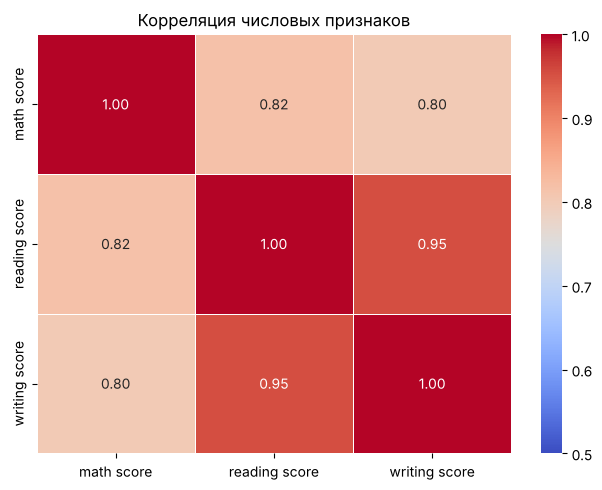

,math score,reading score,writing score
math score,1.000,0.818,0.803
reading score,0.818,1.000,0.955
writing score,0.803,0.955,1.000


In [14]:
corr = df[num_cols].corr()
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=0.5, vmax=1, linewidths=0.5)
plt.title("Корреляция числовых признаков")
plt.tight_layout()
plt.show()
corr.round(3)

## 6. Тренды и зависимости между переменными

Сравним средние баллы по группам категориальных признаков.

In [15]:
cats = ["gender", "test preparation course", "lunch", "race/ethnicity", "parental level of education"]
for c in cats:
    print(f"--- Средние баллы по признаку: {c}")
    print(df.groupby(c)[num_cols].mean().round(1).sort_values("math score", ascending=False))
    print()

--- Средние баллы по признаку: gender
        math score  reading score  writing score
gender                                          
male          68.7           65.5           63.3
female        63.6           72.6           72.5

--- Средние баллы по признаку: test preparation course
                         math score  reading score  writing score
test preparation course                                          
completed                      69.7           73.9           74.4
none                           64.1           66.5           64.5

--- Средние баллы по признаку: lunch
              math score  reading score  writing score
lunch                                                 
standard            70.0           71.7           70.8
free/reduced        58.9           64.7           63.0

--- Средние баллы по признаку: race/ethnicity
                math score  reading score  writing score
race/ethnicity                                          
group E               73.8 

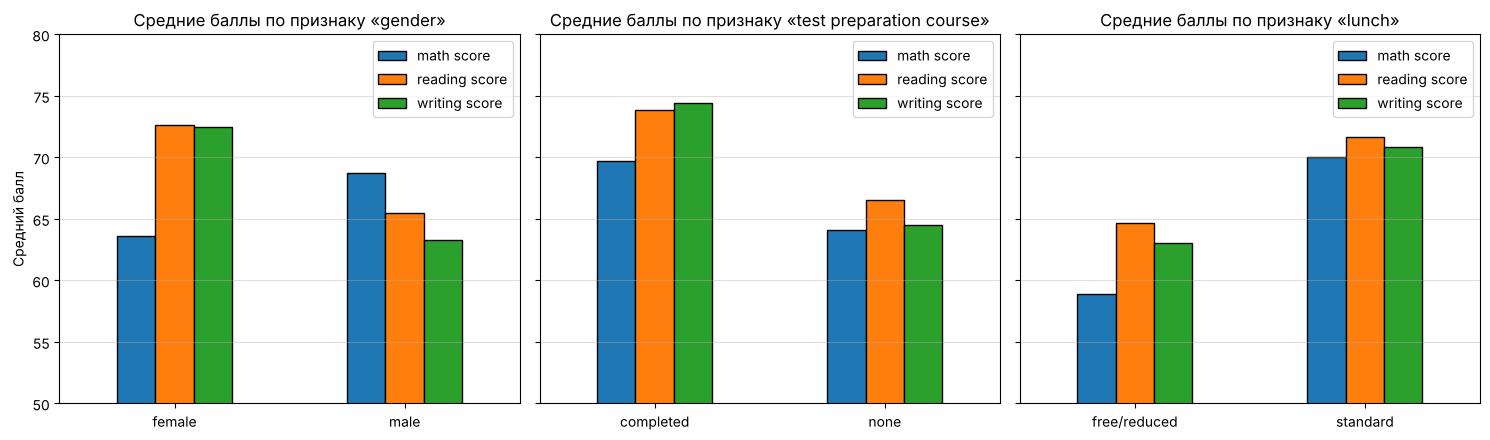

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, c in zip(axes, ["gender", "test preparation course", "lunch"]):
    df.groupby(c)[num_cols].mean().plot(kind="bar", ax=ax, rot=0, edgecolor="black")
    ax.set_title(f"Средние баллы по признаку «{c}»")
    ax.set_xlabel("")
    ax.set_ylim(50, 80)
    ax.grid(axis="y", alpha=0.4)
axes[0].set_ylabel("Средний балл")
plt.tight_layout()
plt.show()

## 7. Аномалии: ученики с нулевыми/очень низкими баллами

In [17]:
low_scores = df[(df[num_cols] < 20).any(axis=1)].sort_values("math score")
print("Учеников с хотя бы одним баллом ниже 20:", len(low_scores))
low_scores

Учеников с хотя бы одним баллом ниже 20: 6


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
59,female,group C,some high school,free/reduced,none,0,17,10
980,female,group B,high school,free/reduced,none,8,24,23
17,female,group B,some high school,free/reduced,none,18,32,28
787,female,group B,some college,standard,none,19,38,32
327,male,group A,some college,free/reduced,none,28,23,19
596,male,group B,high school,free/reduced,none,30,24,15


In [18]:
print("Количество максимальных (100) баллов:")
print((df[num_cols] == 100).sum())
print()
print("Баллы за пределами диапазона 0–100:", ((df[num_cols] < 0) | (df[num_cols] > 100)).sum().sum())

Количество максимальных (100) баллов:
math score        7
reading score    17
writing score    14
dtype: int64

Баллы за пределами диапазона 0–100: 0


## Выводы

1. **Структура данных.** Набор содержит 1000 записей и 8 столбцов: 5 категориальных (`gender`, `race/ethnicity`, `parental level of education`, `lunch`, `test preparation course`) и 3 числовых (`math score`, `reading score`, `writing score`). Типы данных заданы корректно.
2. **Пропуски и дубликаты.** Пропущенных значений и полностью повторяющихся строк нет — данные не требуют дополнительной очистки.
3. **Статистические характеристики.** Средние баллы: math — 66.1, reading — 69.2, writing — 68.1 (стандартные отклонения ≈ 15). Распределения близки к нормальным, с небольшой левой асимметрией (длинный «хвост» в области низких баллов).
4. **Распределения признаков.** Самые многочисленные категории — родители с образованием *some college* (22.6%) и *associate's degree* (22.2%), а также группы *C* (31.9%) и *D* (26.2%). Магистров среди родителей меньше всего (5.9%); группа *A* — самая малочисленная (8.9%).
5. **Зависимости.** Все три балла положительно коррелируют. Особенно сильна связь *reading* — *writing* (r = 0.955); с *math* корреляция ниже (0.82 и 0.80).
6. **Тренды по группам.** Девушки лучше в чтении (72.6 против 65.5) и письме (72.5 против 63.3), юноши лучше в математике (68.7 против 63.6). Ученики, прошедшие подготовительный курс, и ученики со стандартным питанием показывают более высокие баллы по всем предметам. Средний балл по математике растёт от группы *A* (61.6) к группе *E* (73.8).
7. **Аномалии.** По математике есть 8 выбросов снизу (0, 8, 18, 19, 22, 23, 24, 26); один ученик набрал 0 баллов. Значений вне диапазона 0–100 нет. Эти записи выглядят как реальные (очень слабые результаты), поэтому их не удаляли.